In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
import category_encoders as ce
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, make_scorer,classification_report, roc_auc_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
from tensorflow.keras.optimizers import Adam
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold,  cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.utils import compute_class_weight
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

# ETAPA 1: Exploración y Modelo Baseline

### Información básica del dataset:
Los datos que contiene provienen de una entidad financiera, la cual lanzó una campaña de marketing a través de llamadas telefónicas. El objetivo del modelo será clasificar si el cliente se suscribirá a un depósito a plazo fijo o no. 
La variable y=1 representa que el usuario sí se suscribió, mientras que y=0 significa que no. 

In [2]:
#Importamos el dataset
bank_marketing = fetch_ucirepo(id=222) 

#Transformamos en DataFrame las features y los targets
X = bank_marketing.data.features 
y = bank_marketing.data.targets 

In [3]:
#Creamos un data frame unificado
df = pd.concat([X,y],axis=1)
print(f'El dataset tiene: {df.shape[0]} filas, y {df.shape[1]} columnas')
df.head()

El dataset tiene: 45211 filas, y 17 columnas


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [4]:
#Vemos los tipos de datos de cada feature
X.info() 

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
dtypes: int64(7), str(9)
memory usage: 5.5 MB


In [5]:
#Tabla para averiguar variables dudosas (default, poutcome)
bank_marketing.variables

bank_marketing.variables[
    bank_marketing.variables['name'].isin(
        ['default', 'poutcome']
    )
]

,name,role,type,demographic,description,units,missing_values
4,default,Feature,Binary,NaN,has credit in default?,NaN,no
15,poutcome,Feature,Categorical,NaN,outcome of the previous marketing campaign (ca...,NaN,yes


In [6]:
# Binarizar y convertir 'y' en una Serie 1D
y = (y['y'] == 'yes').astype(int) 

# Verificar los resultados
print(y.value_counts())

y
0    39922
1     5289
Name: count, dtype: int64


In [7]:
#Vemos los valores nulos en X
print(X.isnull().sum())

#Vemos si y tiene valores nulos
print(y.isnull().sum())


age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
dtype: int64
0


### Eliminamos columnas

In [8]:
#Eliminamos poutcome ya que tiene demasiados valores nulos (no recuerdo si contact tambien teniamos que eliminarla, x las dudas no la saque)

X = X.drop(columns=['poutcome','contact'])
df = df.drop(columns=['poutcome','contact'])

Saque el reemplazo "unknown" de los nulos de job y education porque los convierte en texto y el procedimiento de KNN implementado, que identifica los faltantes mediante .isna(), deja de detectarlos. (Hay que mantener lo nulos hasta la imputacion con KNN)

In [9]:
#Vemos qué valores únicos tiene cada feature
for col in X:
    print(f'{col} - unique: {X[col].nunique()}')

age - unique: 77
job - unique: 11
marital - unique: 3
education - unique: 3
default - unique: 2
balance - unique: 7168
housing - unique: 2
loan - unique: 2
day_of_week - unique: 31
month - unique: 12
duration - unique: 1573
campaign - unique: 48
pdays - unique: 559
previous - unique: 41


In [10]:
#Vemos si hay registros duplicados
X.duplicated().any()

np.False_

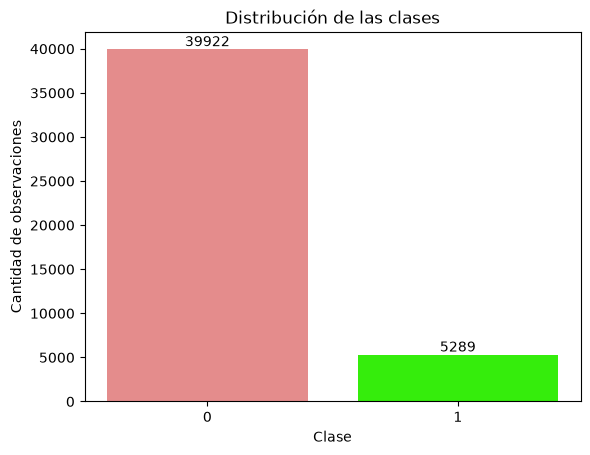

In [11]:
class_counts = y.value_counts().sort_index()

plt.bar(
    class_counts.index.astype(str),
    class_counts.values,
    color=["#E48C8C", "#35ED0C"]
)

plt.xlabel("Clase")
plt.ylabel("Cantidad de observaciones")
plt.title("Distribución de las clases")

for clase, cantidad in zip(class_counts.index.astype(str), class_counts.values):
    plt.text(
        clase,
        cantidad,
        str(cantidad),
        ha="center",
        va="bottom"
    )

plt.show()

Agregamos gráficos de barras apiladas para poder comprender cómo se distribuyen los diferentes valores de las variables categóricas en función de la clase, esto nos permite evaluar si hay ciertos valores que tienen más "peso" en el outcome 

In [12]:
#Definimos las columnas categóricas
categorical_columns = X.select_dtypes(include='str').columns

Se observan diferencias en la distribución de suscripciones según el mes de contacto, destacándose marzo y diciembre. Esto podría sugerir un patrón estacional, aunque el gráfico por sí solo no permite confirmarlo.

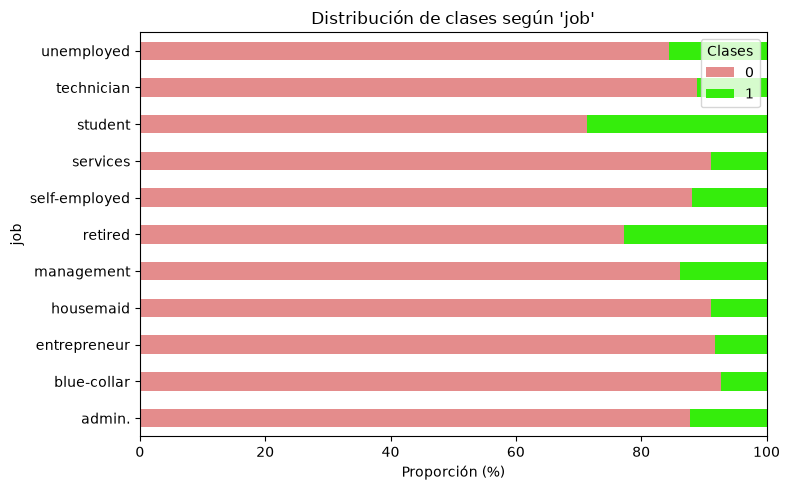

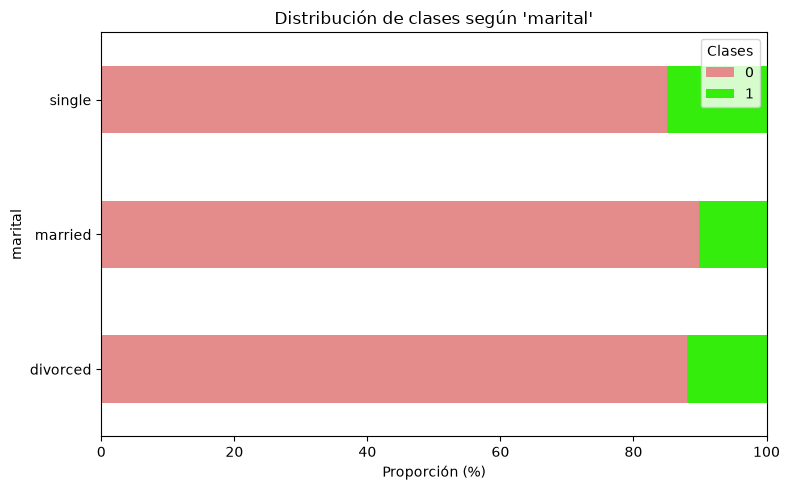

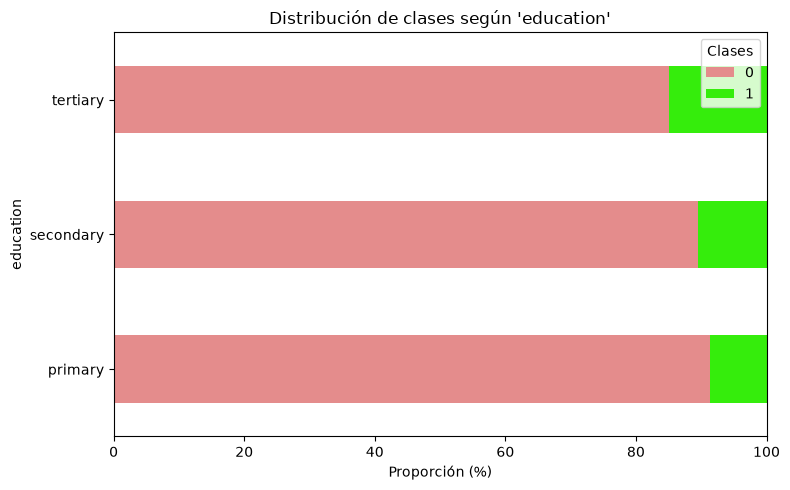

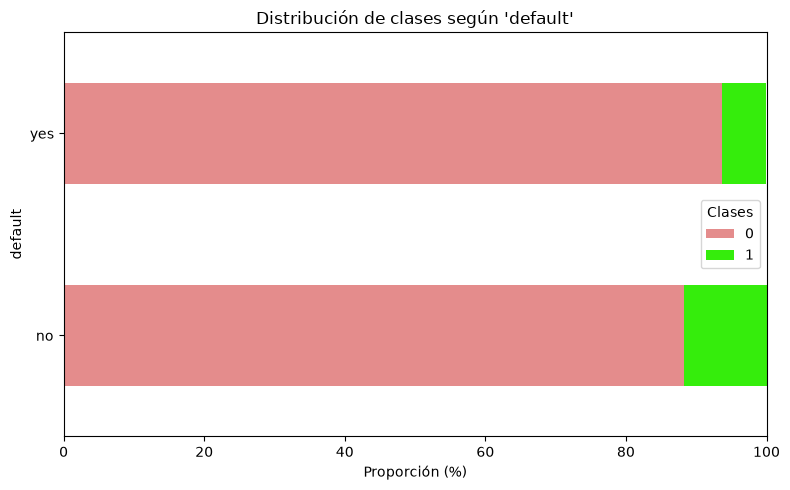

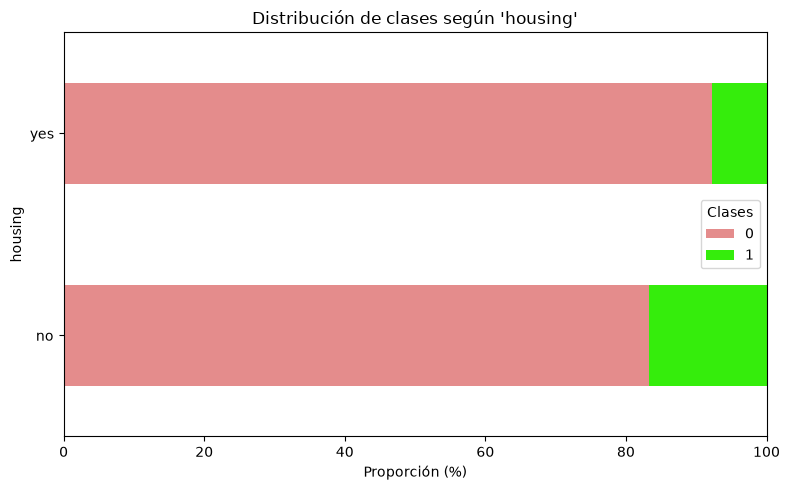

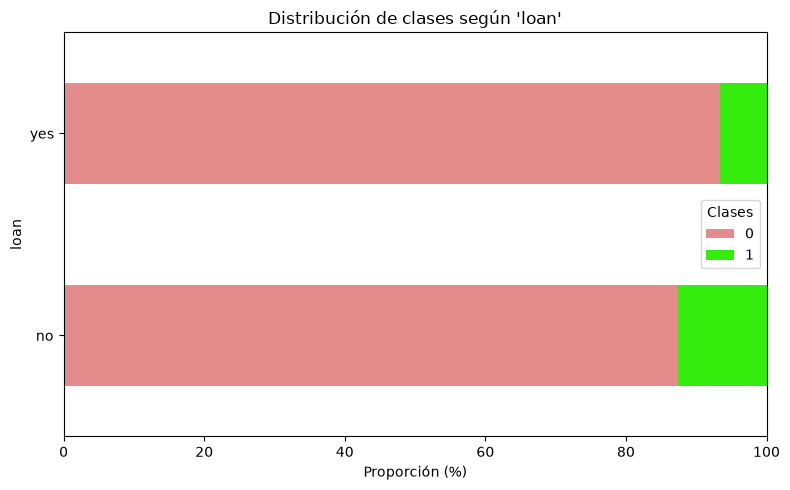

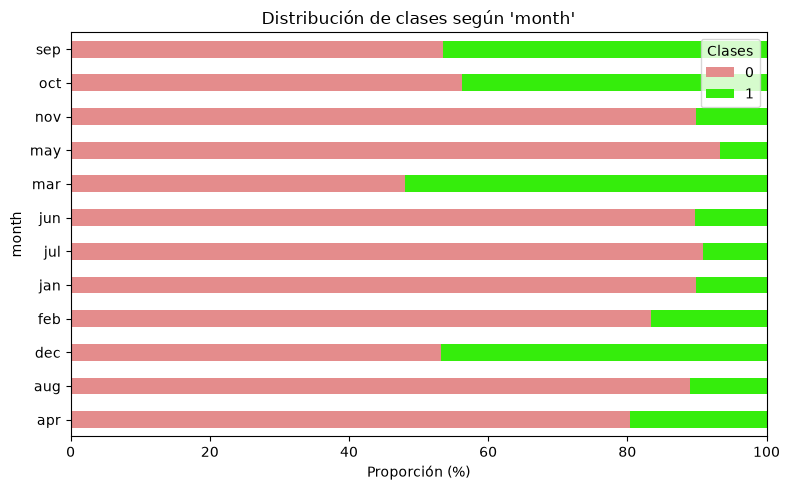

In [13]:
for columna in categorical_columns:

    tabla = pd.crosstab(
        X[columna],
        y,
        normalize="index"
    ).reindex(columns=[0, 1], fill_value=0) * 100

    tabla.plot(
        kind="barh",
        stacked=True,
        figsize=(8, 5),
         color=["#E48C8C", "#35ED0C"]
    )

    plt.title(f"Distribución de clases según '{columna}'")
    plt.xlabel("Proporción (%)")
    plt.ylabel(columna)
    plt.legend(title="Clases")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

### PARTICIÓN Y TRANSFORMACIÓN DE DATOS

Estrategia de partición elegida: Se ha optado por dividir los datos utilizando una estrategia de estratificación, con el objetivo de conservar las proporciones de las clases en cada conjunto, esta decisión se tomó basándonos en el fuerte desbalance entre las clases y la necesidad de que ambas se vean representadas en cada conjunto. 

In [14]:
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")

Datos de Entrenamiento (Train): (36168, 14)
Datos de Desarrollo (Dev): (9043, 14)


In [15]:
#Definimos las variables numéricas (las categóricas ya las definimos antes)
numerical_columns = X.select_dtypes(include=('float','int')).columns

### TRABAJO DE VALORES NULOS CON IMPUTACION KNN
Antes de realizar la imputación mediante K vecinos cercanos (KNN), verificamos nuevamente la cantidad de valores nulos en las columnas job y education.

In [91]:
print(X_train[['job', 'education']].isna().sum())
print(X_train[['job', 'education']].head())

job           234
education    1482
dtype: int64
              job  education
24001  technician  secondary
43409     student  secondary
20669  technician  secondary
18810  unemployed  secondary
23130  technician  secondary


Imputación de valores faltantes en job mediante KNN
Para estimar las ocupaciones faltantes, utilizamos un clasificador de K vecinos cercanos (KNN), con K = 5.

La similitud entre clientes se calcula a partir de las variables age, balance, marital, default, housing y loan. Previamente, escalamos las variables numéricas y codificamos las categóricas.

Para cada cliente con job faltante, buscamos los cinco clientes más similares del conjunto de entrenamiento cuya ocupación es conocida y completamos el dato con la ocupación más frecuente entre ellos.

Aplicamos este procedimiento a los valores faltantes de entrenamiento y validación, utilizando siempre vecinos del conjunto de entrenamiento. Las ocupaciones que ya estaban registradas se mantienen sin cambios.


In [16]:
#Creamos copias de entrenamiento y validación donde completaremos los nulos, conservando los originales.

X_train_imputed = X_train.copy()
X_dev_imputed = X_dev.copy()

X_train.info()

<class 'pandas.DataFrame'>
Index: 36168 entries, 24001 to 44229
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          36168 non-null  int64
 1   job          35934 non-null  str  
 2   marital      36168 non-null  str  
 3   education    34686 non-null  str  
 4   default      36168 non-null  str  
 5   balance      36168 non-null  int64
 6   housing      36168 non-null  str  
 7   loan         36168 non-null  str  
 8   day_of_week  36168 non-null  int64
 9   month        36168 non-null  str  
 10  duration     36168 non-null  int64
 11  campaign     36168 non-null  int64
 12  pdays        36168 non-null  int64
 13  previous     36168 non-null  int64
dtypes: int64(7), str(7)
memory usage: 4.1 MB


Elegimos qué características vamos a comparar para buscar clientes similares.


In [17]:
#Guardamos los nombres de las variables que vamos a usar para el KNN.

columnas_vecinos = [
    'age', 'balance', 'marital',
    'default', 'housing', 'loan'
]
#Preparamos esas características para calcular las distancias: 
#Escalamos edad y saldo, y convertimos las categorías en columnas numéricas.

preparador_knn = ColumnTransformer([
    ('numericas', StandardScaler(), ['age', 'balance']),
    ('categoricas', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ), ['marital', 'default', 'housing', 'loan'])
])

vecinos_train = preparador_knn.fit_transform(
    X_train_imputed[columnas_vecinos]
)

vecinos_dev = preparador_knn.transform(
    X_dev_imputed[columnas_vecinos]
)

In [18]:
"""Para cada trabajo faltante, votan los cinco vecinos más cercanos del entrenamiento. Los trabajos ya registrados se conservan 
y dev no se usa para entrenar KNN."""
 
# Identificamos qué clientes tienen job registrado
job_conocido = X_train_imputed['job'].notna()

knn_job = KNeighborsClassifier(n_neighbors=5)

knn_job.fit(
    vecinos_train[job_conocido],
    X_train_imputed.loc[job_conocido, 'job']
)

# Completamos los faltantes de train y dev
for datos, vecinos in [
    (X_train_imputed, vecinos_train),
    (X_dev_imputed, vecinos_dev)
]:
    job_faltante = datos['job'].isna()

    if job_faltante.any():
        datos.loc[job_faltante, 'job'] = knn_job.predict(
            vecinos[job_faltante]
        )
        
#Verificamos que ya no haya valores nulos en job

print("Nulos en train:", X_train_imputed['job'].isna().sum())
print("Nulos en dev:", X_dev_imputed['job'].isna().sum())

Nulos en train: 0
Nulos en dev: 0


Realizamos el mismo procedimiento para el tratamiento de valores nulos de la variable education

In [19]:
# Identificamos qué clientes tienen education registrada
education_conocida = X_train_imputed['education'].notna()

knn_education = KNeighborsClassifier(n_neighbors=5)

knn_education.fit(
    vecinos_train[education_conocida],
    X_train_imputed.loc[education_conocida, 'education']
)

# Completamos los faltantes de train y dev
for datos, vecinos in [
    (X_train_imputed, vecinos_train),
    (X_dev_imputed, vecinos_dev)
]:
    education_faltante = datos['education'].isna()

    if education_faltante.any():
        datos.loc[education_faltante, 'education'] = (
            knn_education.predict(vecinos[education_faltante])
        )
        
#Verificamos que ya no haya valores nulos en education

print("Nulos en train:", X_train_imputed['education'].isna().sum())
print("Nulos en dev:", X_dev_imputed['education'].isna().sum())

Nulos en train: 0
Nulos en dev: 0


In [20]:
#Creamos los transformadores
OneHot_Encoder = OneHotEncoder(drop='first',handle_unknown='error',sparse_output=False)
Scaler = StandardScaler()

Transformer = make_column_transformer(
    (OneHot_Encoder, categorical_columns),
    (Scaler, numerical_columns),
    remainder='passthrough'
    
)

#Transformamos las variables
X_train_transformed = Transformer.fit_transform(X_train_imputed)
X_dev_transformed = Transformer.transform(X_dev_imputed)

# TECNNICAS DE OVER Y UNDER SAMPLING

### Implementamos técnica Tomek Link de Undersampling para buscar pares de clientes que son vecinos más cercanos entre sí, pero pertenecen a clases diferentes: uno se suscribió y el otro no.

In [21]:
print("Antes:")
print(y_train.value_counts())

# Instanciar el método
tl = TomekLinks(sampling_strategy="auto") #auto para la mayoritaria

# Aplicar undersampling
X_train_tl, y_train_tl = tl.fit_resample(X_train_transformed, y_train)

print("\nDespués:")
print(y_train_tl.value_counts())

#Hacemos esto para no tener que modificar el resto del código, que hace referencia a X_train y y_train.
X_train_transformed = X_train_tl
y_train = y_train_tl


Antes:
y
0    31937
1     4231
Name: count, dtype: int64

Después:
y
0    31016
1     4231
Name: count, dtype: int64


### Agregamos técnica SMOTE de oversampling para la clase minoritaria

In [22]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_transformed,
    y_train
)

print("Distribución original:")
print(y_train.value_counts())

print("\nDistribución después de SMOTE:")
print(y_train_smote.value_counts())

X_train_transformed = X_train_smote
y_train = y_train_smote

Distribución original:
y
0    31016
1     4231
Name: count, dtype: int64

Distribución después de SMOTE:
y
0    31016
1    31016
Name: count, dtype: int64


### Para aplicar primero SMOTE y despuues TomekLinks

In [44]:
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_transformed,
    y_train
)

X_train_transformed = X_train_smote
y_train = y_train_smote

# Instanciar el método
tl = TomekLinks(sampling_strategy="all") #all ya que ahora no hay clase minoritaria (elimine la semilla xq tira error en tomeklinks)

# Aplicar undersampling
X_train_tl, y_train_tl = tl.fit_resample(X_train_transformed, y_train)

#Hacemos esto para no tener que modificar el resto del código, que hace referencia a X_train y y_train.
X_train_transformed = X_train_tl
y_train = y_train_tl



### Implementación de modelo baseline simple
En este caso, se ha decidido implementar una regresión logística simple. 


In [24]:
modelo_base = LogisticRegression(C=1, max_iter=10000, verbose=3)
modelo_base.fit(X_train_transformed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",3
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None


### Evaluación de métricas
Hemos optado por definir el Recall como métrica principal. La razón de dicha decisión es que, el objetivo del modelo es captar a aquellas personas que se suscribirán (o podrían suscribirse) al depósito del banco, es decir, estamos interesados en capturar a los casos positivos, y evitar falsos negativos, ya que esto significaría perder potenciales clientes (personas que tenian altas chances de suscribirse). Teniendo en cuenta el contexto de marketing (la campaña de la cual proviene este dataset), es fundamental que, si una persona tiene chances de suscribirse, la podamos "captar". Es por esta razón que nuestra métrica adecuada a maximizar será el recall.

In [26]:
# 4. Evaluación en el conjunto de Desarrollo (Dev)
y_pred_dev = modelo_base.predict(X_dev_transformed)

# Cálculos de Métricas
matriz_conf = confusion_matrix(y_dev, y_pred_dev)
exactitud = accuracy_score(y_dev, y_pred_dev)
precision = precision_score(y_dev, y_pred_dev)
recall = recall_score(y_dev, y_pred_dev)
f1 = f1_score(y_dev, y_pred_dev) 

print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
print("Matriz de Confusión:")
print(matriz_conf)
print(f"Exactitud (Accuracy): {exactitud:.4f}")
print(f"Precisión:            {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntaje F1 (F1-Score): {f1:.4f}")


--- RESULTADOS EN EL CONJUNTO DEV ---
Matriz de Confusión:
[[6589 1396]
 [ 217  841]]
Exactitud (Accuracy): 0.8216
Precisión:            0.3759
Exhaustividad (Recall):0.7949
Puntaje F1 (F1-Score): 0.5105


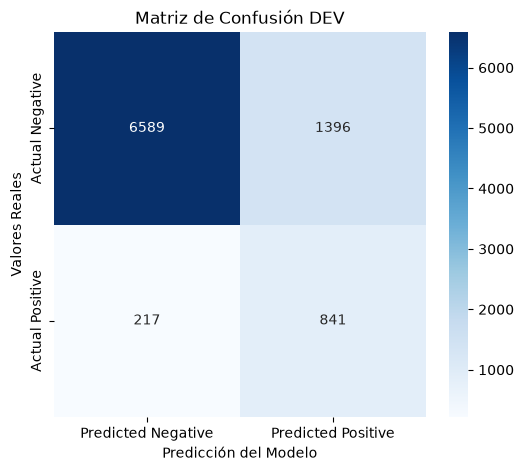

In [27]:
# Crear un mapa de calor de la matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión DEV')
plt.show()

Analizamos el peso de las variables juntas

In [28]:
# Recall original, antes de mezclar variables
pred_original = modelo_base.predict(
    Transformer.transform(X_dev_imputed)
)

recall_original = recall_score(y_dev, pred_original)

print("Recall original:", recall_original)

Recall original: 0.7948960302457467


Comenzamos con Month para probar:
Podemos observar que el modelo utiliza la información del mes para detectar suscriptores. Al desordenarla entre clientes, perdió parte de esa capacidad.

In [29]:
# Copiamos dev para conservar los datos originales
X_dev_permutado = X_dev_imputed.copy()

# Mezclamos únicamente los meses entre clientes
rng = np.random.default_rng(42)
X_dev_permutado['month'] = rng.permutation(
    X_dev_permutado['month'].to_numpy()
)

# Predecimos sin volver a entrenar el modelo ni el transformador
pred_permutada = modelo_base.predict(
    Transformer.transform(X_dev_permutado)
)

recall_permutado = recall_score(y_dev, pred_permutada)

print("Recall original:", recall_original)
print("Recall con month mezclado:", recall_permutado)
print("Caída del recall:", recall_original - recall_permutado)

Recall original: 0.7948960302457467
Recall con month mezclado: 0.7164461247637051
Caída del recall: 0.07844990548204167


Analizamos el peso de las demás variables:

In [30]:
rng = np.random.default_rng(42)
resultados_importancia = []

for columna in X_dev_imputed.columns:
    caidas = []

    for repeticion in range(10):
        X_permutado = X_dev_imputed.copy()

        X_permutado[columna] = rng.permutation(
            X_permutado[columna].to_numpy()
        )

        pred = modelo_base.predict(
            Transformer.transform(X_permutado)
        )

        recall_mezclado = recall_score(y_dev, pred)
        caidas.append(recall_original - recall_mezclado)

    resultados_importancia.append({
        'Variable': columna,
        'Caida_recall_media': np.mean(caidas),
        'Desviacion': np.std(caidas)
    })

importancias_baseline = (
    pd.DataFrame(resultados_importancia)
    .sort_values('Caida_recall_media', ascending=False)
    .reset_index(drop=True)
)

importancias_baseline

,Variable,Caida_recall_media,Desviacion
0,duration,0.324480,0.007644
1,month,0.091115,0.006343
2,housing,0.046030,0.005348
3,campaign,0.022212,0.006975
4,previous,0.018809,0.003953
5,job,0.017108,0.006649
6,education,0.016257,0.005208
7,pdays,0.015217,0.002552
8,loan,0.011720,0.002543
9,day_of_week,0.004915,0.002421


Podemos observar que la variable duration es la que más influye, al mezclarla el recall pasa de 79,49% a 47% aproximadamente. 
Esto indica que el modelo depende mucho del tiempo de llamada, al mezclar los tiempos entre clientes, rompemos su relación con la suscripción. 

### Conservación de la variable duration:
Se decidió conservar la variable duration debido a su aporte al recall en las pruebas realizadas. Sin embargo, reconocemos que su valor solo se conoce una vez finalizada la llamada y, por lo tanto, no está disponible al momento de seleccionar a qué clientes contactar.

Esta decisión limita la aplicación del modelo: las métricas obtenidas corresponden a un escenario con duración conocida y no pueden trasladarse directamente a la selección de clientes antes de llamarlos. Para ese objetivo, sería necesario entrenar y evaluar una versión del modelo sin esta variable.

c:\TP Final IA\ClasificacionBanco_IA\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
5 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "c:\TP Final IA\ClasificacionBanco_IA\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\TP Final IA\ClasificacionBanco_IA\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\TP Final IA\ClasificacionBanco_IA\.venv\Lib\site-package

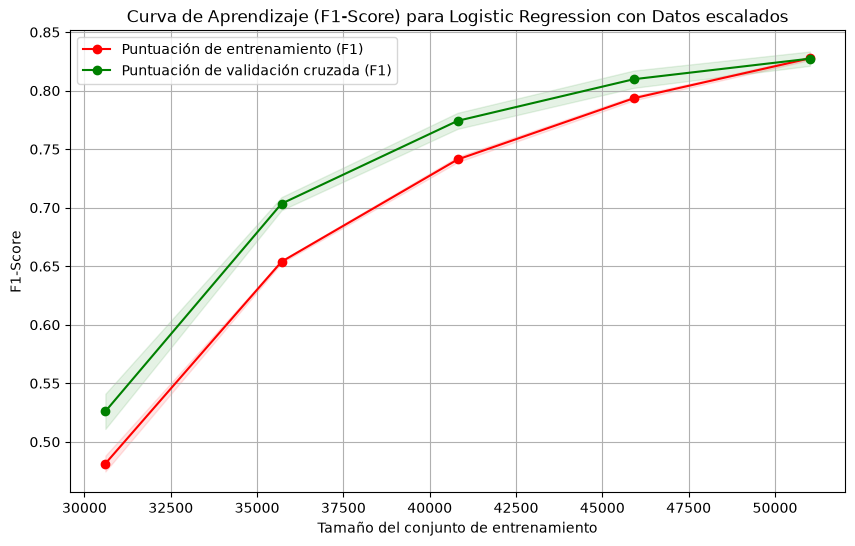

In [47]:
# Definir el scorer para F1-score
f1_scorer = make_scorer(f1_score)

# Generar la curva de aprendizaje con los datos de entrenamiento sin escalar
train_sizes, train_scores, test_scores = learning_curve(
    modelo_base, X_train_transformed, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring=f1_scorer
)

# Calcular medias y desviaciones estándar
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

# Plotear la curva de aprendizaje
plt.figure(figsize=(10, 6))
plt.title("Curva de Aprendizaje (F1-Score) para Logistic Regression con Datos escalados")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("F1-Score")
plt.grid()

plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1,
                 color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1,
                 color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
         label="Puntuación de entrenamiento (F1)")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
         label="Puntuación de validación cruzada (F1)")

plt.legend(loc="best")
plt.show()

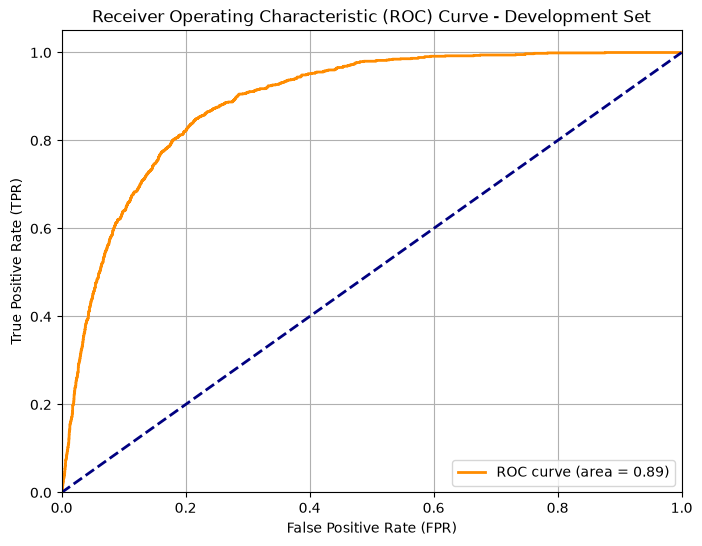

In [ ]:
# Obtener las probabilidades de predicción para la clase positiva en el conjunto de desarrollo
y_pred_proba_dev = modelo_base.predict_proba(X_dev_transformed)[:, 1]

# Calcular la curva ROC
fpr, tpr, thresholds = roc_curve(y_dev, y_pred_proba_dev)
roc_auc = auc(fpr, tpr)

# Plotear la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve - Development Set')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
nombres_caracteristicas = Transformer.get_feature_names_out()
nombres_caracteristicas = [
    nombre.split('__', 1)[1]
    for nombre in nombres_caracteristicas
]

coeficientes = modelo_base.coef_[0]

#print(f"El punto de partida de la ecuación (Intercepto) es: {sesgo:.4f}\n")


# Creamos el DataFrame
importancia_variables = pd.DataFrame({
    'Característica': nombres_caracteristicas,
    'Peso (Coeficiente)': coeficientes
})

# Calculamos el impacto absoluto
importancia_variables['Impacto Absoluto'] = (
    importancia_variables['Peso (Coeficiente)'].abs()
)

# Ordenamos de mayor a menor impacto
importancia_variables = importancia_variables.sort_values(
    by='Impacto Absoluto',
    ascending=False
)
print("--- TOP 10 VARIABLES CON MÁS IMPACTO ---")
print(importancia_variables.head(10)[['Característica', 'Peso (Coeficiente)', 'Impacto Absoluto']])

--- TOP 10 VARIABLES CON MÁS IMPACTO ---
   Característica  Peso (Coeficiente)  Impacto Absoluto
25      month_mar            1.432366          1.432366
22      month_jan           -1.192419          1.192419
33       duration            1.057358          1.057358
26      month_may           -0.998023          0.998023
20      month_dec            0.927432          0.927432
28      month_oct            0.861993          0.861993
17    housing_yes           -0.856631          0.856631
29      month_sep            0.853909          0.853909
27      month_nov           -0.800369          0.800369
23      month_jul           -0.735626          0.735626


/var/folders/77/8wfmp3hx6_v0440sd1_2lfnr0000gp/T/ipykernel_27061/390684523.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


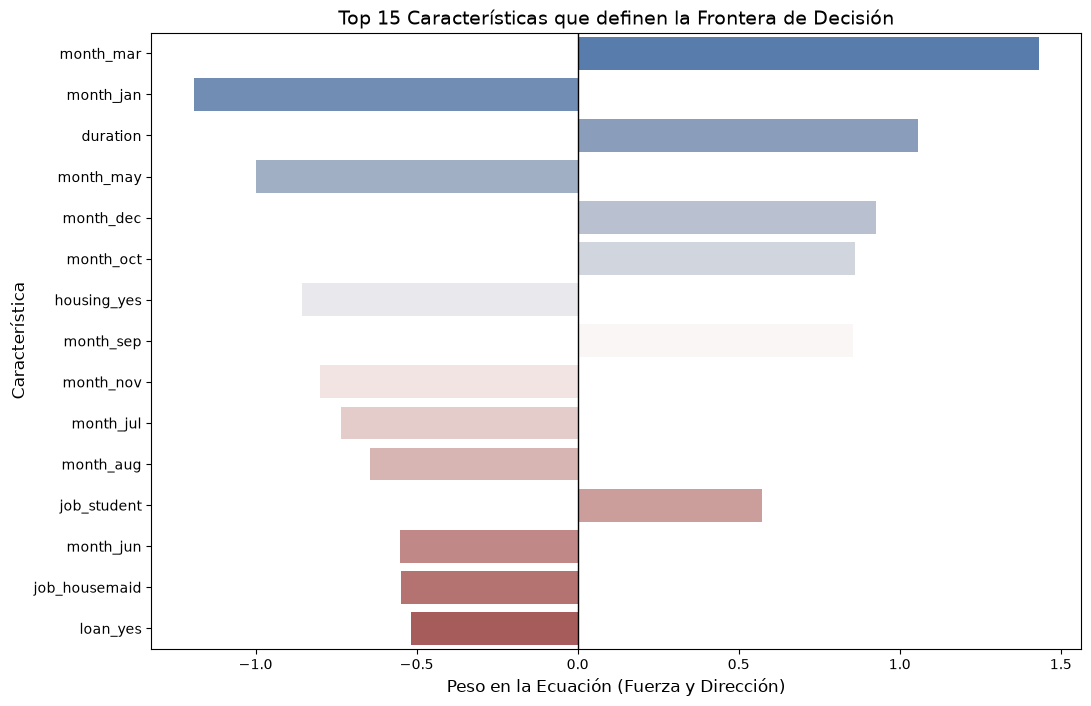

In [ ]:
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Peso (Coeficiente)',
    y='Característica',
    data=importancia_variables.head(15),
    palette='vlag'
)
plt.title('Top 15 Características que definen la Frontera de Decisión', fontsize=14)
plt.xlabel('Peso en la Ecuación (Fuerza y Dirección)',fontsize=12)
plt.ylabel('Característica',fontsize=12)
plt.axvline(0, color='black', linewidth=1)
plt.show()

## Etapa 2 — Red neuronal multicapa y análisis de errores 

### Análisis de errores manual
Los errores del modelo baseline pueden ser catalogados como errores de sesgo (underfitting), ya que el modelo simplemente no puede identificar de manera correcta los casos positivos (posee un recall de 0.3535), y no se presenta una gran varianza respecto al test, el cual indica un recall de 0.3422.

#### **4.2.1.** Seleccionamos 50 casos mal clasificados y los evaluamos 


In [ ]:
resultados = X_dev

resultados['y_real'] = y_dev
resultados['y_pred'] = y_pred_dev

errores = resultados[resultados['y_real'] != resultados['y_pred']]

muestra_errores = errores.sample(n=min(50,len(errores)),random_state = 42)

In [ ]:
muestra_errores.head(25)

,age,job,marital,education,default,balance,housing,loan,day_of_week,month,duration,campaign,pdays,previous,y_real,y_pred
16796,45,management,married,tertiary,no,1034,no,yes,24,jul,1820,4,-1,0,0,1
42073,41,unemployed,married,tertiary,no,0,no,no,30,oct,373,3,-1,0,1,0
44141,31,management,single,tertiary,no,2907,yes,no,12,jul,248,1,194,3,1,0
33452,36,management,single,tertiary,no,20,yes,no,20,apr,766,2,150,3,0,1
27698,42,management,married,tertiary,no,5,no,no,21,nov,1067,2,-1,0,0,1
41198,35,management,single,tertiary,no,1756,no,no,20,aug,195,1,-1,0,1,0
41438,26,technician,single,secondary,no,1231,yes,no,4,sep,230,1,93,7,1,0
40523,38,student,married,Unknown,no,0,no,no,8,jul,341,1,385,1,1,0
22354,41,technician,married,secondary,no,965,no,no,22,aug,336,10,-1,0,1,0
42163,54,technician,married,secondary,no,0,no,no,6,nov,464,5,192,8,1,0


### Categorización de errores:
**A simple vista** podemos notar que los datos mal clasificados, al menos en la muestra, suelen tener datos "unknown" en alguna de sus columnas. Podemos inferir que el modelo no tiene la capacidad suficiente para clasficar, o que la categorización "unknown" confunde al modelo, impidiéndole clasificar de manera correcta. 


Para enfrentar el sesgo de nuestro modelo debemos cambiar su arquitectura y aumentar capacidad, ya que necesitamos que el modelo sea capaz de aprender patrones más complejos para aumentar su capacidad predictiva. Incorporamos una red neuronal con la siguiente arquitectura:
()

### 4.2.2. ARQUITECTURA ML: CREAMOS RED NEURONAL **SIN** REGULARIZACIÓN

In [ ]:
model = Sequential([
    # Capa de entrada y primera capa oculta con activación ReLU y regularización L2
    Dense(128, activation='relu', input_shape=(X_train_transformed.shape[1],)),

    # Segunda capa oculta con activación ReLU y regularización L2
    Dense(64, activation='relu'),

    # Tercera capa oculta con activación ReLU y regularización L2
    Dense(32, activation='relu'),

    # Capa de salida con activación sigmoide para clasificación binaria
    Dense(1, activation='sigmoid')
])

# Instanciar el optimizador
opt = Adam(learning_rate=0.0001)

model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['recall']
)
# Mostrar un resumen del modelo
#print("\nResumen del modelo de red neuronal:")
#model.summary()

/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Definir la llamada de Early Stopping
# Monitorea la 'val_loss' (pérdida en el conjunto de validación)
# 'patience=10' significa que esperará 10 épocas sin mejora antes de detenerse
# 'restore_best_weights=True' restaurará los pesos del modelo de la mejor época



early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

"""Como vimos que reduciendo la tasa de aprendizaje de adam converge mejor, podemos usar ReduceROnPlateau para
que cuando la val_loss se estanque, reduzca la tasa de aprendizaje automaticamente reduciendola un poco mas para
mejor convergrncia"""

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#Definimos los pesos
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weight = dict(zip(classes, weights))

# Entrenar el modelo
print("\nEntrenando el modelo...")
history = model.fit(
    X_train_transformed, y_train,
    epochs=100, 
    batch_size=64, 
    validation_data=(X_dev_transformed, y_dev), # Datos de validación
    class_weight=class_weight, #aca aplicamos los pesos de clase para balancear el desbalance
    callbacks=[early_stopping, reduce_lr], # Aplicar Early Stopping #Agregue acá reduce_lr para el ajuste de tasa de adam automatico
    verbose=1 
)

print("\nEntrenamiento completado.")


Entrenando el modelo...
Epoch 1/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 1s 744us/step - loss: 0.5303 - recall: 0.7034 - val_loss: 0.4362 - val_recall: 0.7845 - learning_rate: 1.0000e-04
Epoch 2/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 551us/step - loss: 0.4197 - recall: 0.8341 - val_loss: 0.4443 - val_recall: 0.8450 - learning_rate: 1.0000e-04
Epoch 3/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step - loss: 0.3980 - recall: 0.8572 - val_loss: 0.4089 - val_recall: 0.8384 - learning_rate: 1.0000e-04
Epoch 4/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 630us/step - loss: 0.3861 - recall: 0.8636 - val_loss: 0.4074 - val_recall: 0.8478 - learning_rate: 1.0000e-04
Epoch 5/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 545us/step - loss: 0.3783 - recall: 0.8695 - val_loss: 0.3846 - val_recall: 0.8355 - learning_rate: 1.0000e-04
Epoch 6/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 642us/step - loss: 0.3732 - recall: 0.8733 - val_loss: 0.4260 - val_recall: 0.8762 - learning_rate: 1.0000e-04
Epoch 7/100
566/566 ━━━━━━━━━━━━━━━━━━━━ 0s 5

\Recall del modelo en el conjunto de prueba: 0.8497
Pérdida del modelo en el conjunto de prueba: 0.3579


<>:3: SyntaxWarning: invalid escape sequence '\R'
<>:3: SyntaxWarning: invalid escape sequence '\R'
/var/folders/77/8wfmp3hx6_v0440sd1_2lfnr0000gp/T/ipykernel_27061/3294539700.py:3: SyntaxWarning: invalid escape sequence '\R'
  print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 287us/step

Reporte de clasificación en el conjunto de prueba:
              precision    recall  f1-score   support

           0       0.98      0.80      0.88      7985
           1       0.37      0.89      0.52      1058

    accuracy                           0.81      9043
   macro avg       0.67      0.84      0.70      9043
weighted avg       0.91      0.81      0.84      9043



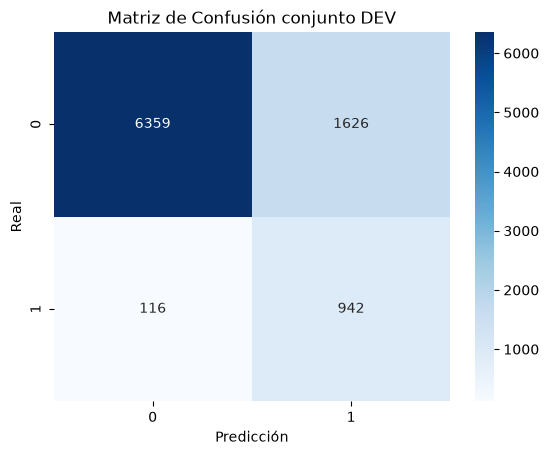

In [ ]:
# Evaluar el modelo en el conjunto de prueba
loss, recall = model.evaluate(X_dev_transformed, y_dev, verbose=0)
print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")
print(f"Pérdida del modelo en el conjunto de prueba: {loss:.4f}")


# Realizar predicciones en el conjunto de prueba
y_pred_proba = model.predict(X_dev_transformed)
y_pred = (y_pred_proba > 0.4).astype(int) # Convertir probabilidades a clases binarias (0 o 1)

# Mostrar el reporte de clasificación
print("\nReporte de clasificación en el conjunto de prueba:")
print(classification_report(y_dev, y_pred))

# Mostrar la matriz de confusión
cm = confusion_matrix(y_dev, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión conjunto DEV')
plt.show()

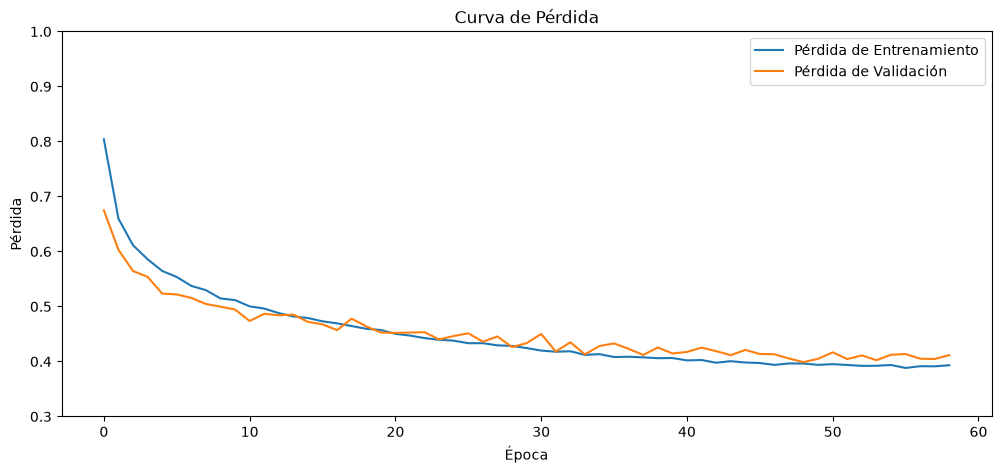

In [ ]:
# Visualizar la historia del entrenamiento para detectar sobreajuste
# Curvas de pérdida
plt.figure(figsize=(12, 5))
plt.ylim(0.3, 1)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Curva de Pérdida')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

# 4.2.3. TÉCNICAS DE REGULARIZACIÓN: AGREGAMOS RED NEURONAL **CON** REGULARIZACIÓN

In [ ]:
model = Sequential([
    # Capa de entrada y primera capa oculta con activación ReLU y regularización L2
    Dense(128, activation='relu', input_shape=(X_train_transformed.shape[1],), kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout para mitigar el sobreajuste

    # Segunda capa oculta con activación ReLU y regularización L2
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout

    # Tercera capa oculta con activación ReLU y regularización L2
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3), # Capa Dropout

    # Capa de salida con activación sigmoide para clasificación binaria
    Dense(1, activation='sigmoid')
])

# Compilamos el modelo: usamos 'Adam' como optimizador, 'binary_crossentropy' como función de pérdida para clasificación binaria, y 'recall' como métrica principal.

# Instanciar el optimizador
opt = Adam(learning_rate=0.0001)

model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['recall']
)
# Mostrar un resumen del modelo
print("\nResumen del modelo de red neuronal:")
model.summary()


Resumen del modelo de red neuronal:


/Users/Camila/Desktop/TrabajoIA/BankMarketingClasificacion_IA/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 128)            │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Definir la llamada de Early Stopping
# Monitorea la 'val_loss' (pérdida en el conjunto de validación)
# 'patience=10' significa que esperará 10 épocas sin mejora antes de detenerse
# 'restore_best_weights=True' restaurará los pesos del modelo de la mejor época



early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

"""Como vimos que reduciendo la tasa de aprendizaje de adam converge mejor, podemos usar ReduceROnPlateau para
que cuando la val_loss se estanque, reduzca la tasa de aprendizaje automaticamente reduciendola un poco mas para
mejor convergrncia"""

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#Definimos los pesos
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
class_weight = dict(zip(classes, weights))

# Entrenar el modelo
print("\nEntrenando el modelo...")
history = model.fit(
    X_train_transformed, y_train,
    epochs=100, 
    batch_size=64, 
    validation_data=(X_dev_transformed, y_dev), # Datos de validación
    class_weight=class_weight, #aca aplicamos los pesos de clase para balancear el desbalance
    callbacks=[early_stopping, reduce_lr], # Aplicar Early Stopping #Agregue acá reduce_lr para el ajuste de tasa de adam automatico
    verbose=1 
)

print("\nEntrenamiento completado.")


Entrenando el modelo...
Epoch 1/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 2s 784us/step - loss: 0.7080 - recall: 0.7175 - val_loss: 0.5908 - val_recall: 0.8195 - learning_rate: 1.0000e-04
Epoch 2/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 754us/step - loss: 0.5716 - recall: 0.8485 - val_loss: 0.5486 - val_recall: 0.8554 - learning_rate: 1.0000e-04
Epoch 3/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 752us/step - loss: 0.5303 - recall: 0.8784 - val_loss: 0.5184 - val_recall: 0.8592 - learning_rate: 1.0000e-04
Epoch 4/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 637us/step - loss: 0.5011 - recall: 0.8905 - val_loss: 0.5048 - val_recall: 0.8658 - learning_rate: 1.0000e-04
Epoch 5/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 601us/step - loss: 0.4789 - recall: 0.8944 - val_loss: 0.4773 - val_recall: 0.8563 - learning_rate: 1.0000e-04
Epoch 6/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 602us/step - loss: 0.4621 - recall: 0.8977 - val_loss: 0.4688 - val_recall: 0.8629 - learning_rate: 1.0000e-04
Epoch 7/100
999/999 ━━━━━━━━━━━━━━━━━━━━ 1s 5

In [ ]:
# Evaluar el modelo en el conjunto de prueba
loss, recall = model.evaluate(X_dev_transformed, y_dev, verbose=0)
print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")
print(f"Pérdida del modelo en el conjunto de prueba: {loss:.4f}")


# Realizar predicciones en el conjunto de prueba
y_pred_proba = model.predict(X_dev_transformed)
y_pred = (y_pred_proba > 0.4).astype(int) # Convertir probabilidades a clases binarias (0 o 1)

# Mostrar el reporte de clasificación
print("\nReporte de clasificación en el conjunto de prueba:")
print(classification_report(y_dev, y_pred))

\Recall del modelo en el conjunto de prueba: 0.8393
Pérdida del modelo en el conjunto de prueba: 0.3640
  1/283 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step

<>:3: SyntaxWarning: invalid escape sequence '\R'
<>:3: SyntaxWarning: invalid escape sequence '\R'
/var/folders/77/8wfmp3hx6_v0440sd1_2lfnr0000gp/T/ipykernel_27061/1254660944.py:3: SyntaxWarning: invalid escape sequence '\R'
  print(f"\Recall del modelo en el conjunto de prueba: {recall:.4f}")


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step

Reporte de clasificación en el conjunto de prueba:
              precision    recall  f1-score   support

           0       0.98      0.81      0.89      7985
           1       0.38      0.86      0.53      1058

    accuracy                           0.82      9043
   macro avg       0.68      0.84      0.71      9043
weighted avg       0.91      0.82      0.85      9043



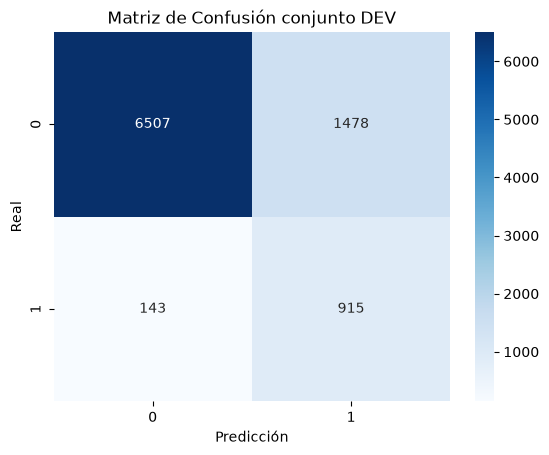

In [ ]:
# Mostrar la matriz de confusión
cm = confusion_matrix(y_dev, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión conjunto DEV')
plt.show()

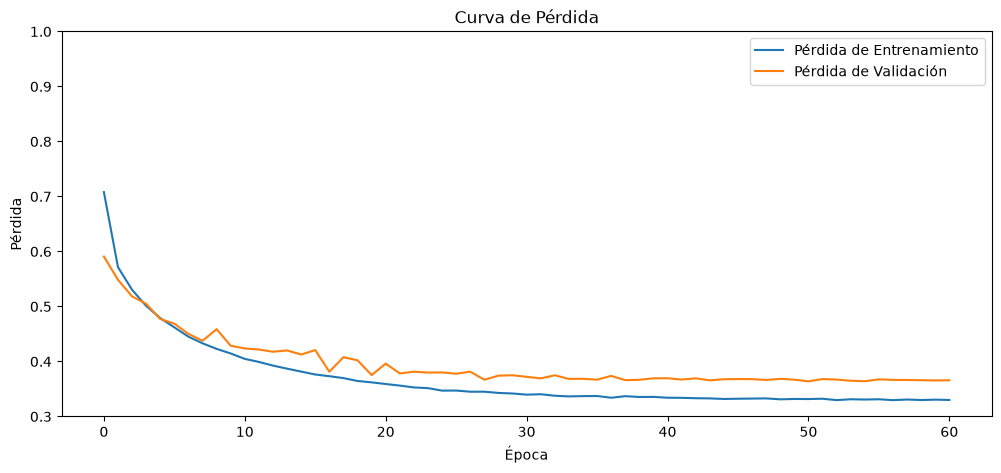

In [ ]:
# Visualizar la historia del entrenamiento para detectar sobreajuste
# Curvas de pérdida
plt.figure(figsize=(12, 5))
plt.ylim(0.3, 1)
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de Validación')
plt.title('Curva de Pérdida')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

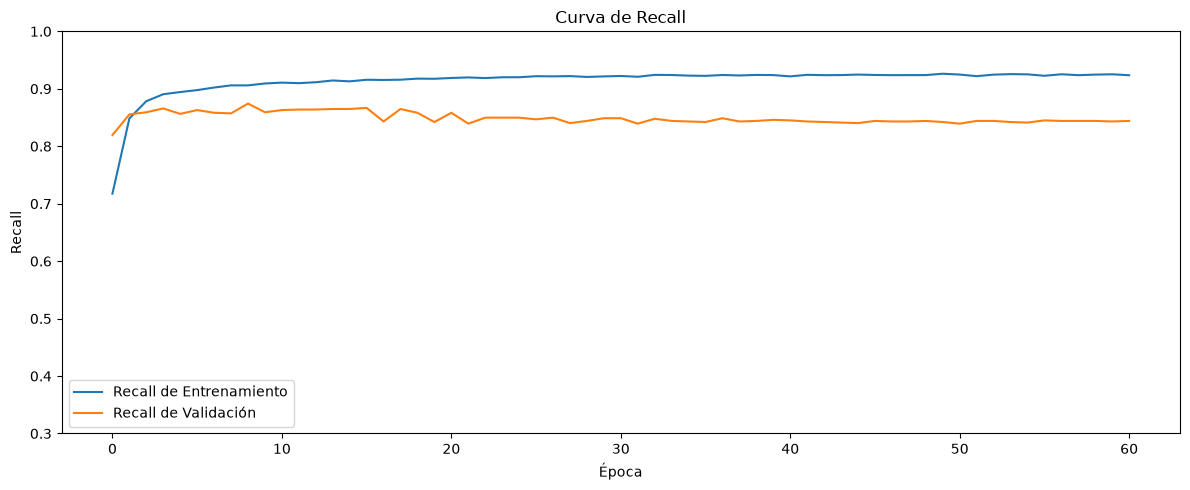

In [ ]:
# Curvas de precisión
#plt.subplot(1, 2, 2)
plt.figure(figsize=(12, 5))
plt.ylim(0.3, 1)
plt.plot(history.history['recall'], label='Recall de Entrenamiento')
plt.plot(history.history['val_recall'], label='Recall de Validación')
plt.title('Curva de Recall')
plt.xlabel('Época')
plt.ylabel('Recall')
plt.legend()

plt.tight_layout()
plt.show()

### Buscamos el umbral de decisión óptimo

In [ ]:
y_prob = model.predict(X_dev_transformed).ravel()

thresholds_to_test = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds_to_test:

    # Convertir probabilidades en clases
    y_pred = (y_prob >= threshold).astype(int)

    # Obtener matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_dev,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Calcular métricas
    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_dev, y_pred),
        "Precision": precision_score(
            y_dev, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_dev, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_dev, y_pred, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

df_thresholds = pd.DataFrame(results)

df_thresholds


283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 237us/step


,Threshold,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,0.10,0.637178,0.241090,0.978261,0.386844,4727,3258,23,1035
1,0.15,0.685945,0.267120,0.965974,0.418509,5181,2804,36,1022
2,0.20,0.720557,0.289360,0.953686,0.444004,5507,2478,49,1009
3,0.25,0.741900,0.304654,0.940454,0.460222,5714,2271,63,995
4,0.30,0.760699,0.319752,0.927221,0.475521,5898,2087,77,981
5,0.35,0.778060,0.335529,0.914934,0.490997,6068,1917,90,968
6,0.40,0.792768,0.349890,0.898866,0.503708,6218,1767,107,951
7,0.45,0.807697,0.366836,0.886578,0.518949,6366,1619,120,938
8,0.50,0.819308,0.380795,0.869565,0.529649,6489,1496,138,920
9,0.55,0.832135,0.398500,0.853497,0.543321,6622,1363,155,903


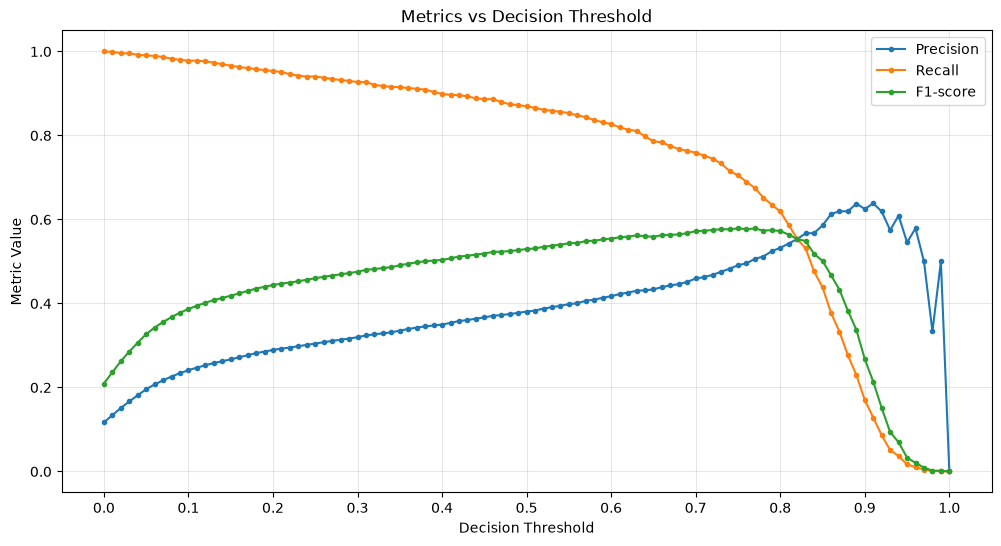

In [ ]:
#Creamos gráfico
thresholds = np.linspace(0, 1, 101)

precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:

    y_pred = (y_pred_proba >= threshold).astype(int)
    precision_values.append(precision_score(y_dev, y_pred, zero_division=0))
    recall_values.append( recall_score(y_dev, y_pred, zero_division=0))
    f1_values.append( f1_score(y_dev, y_pred, zero_division=0) )
plt.figure(figsize=(12, 6))

plt.plot(
    thresholds,
    precision_values,
    label="Precision",
    marker="."
)

plt.plot(
    thresholds,
    recall_values,
    label="Recall",
    marker="."
)

plt.plot(
    thresholds,
    f1_values,
    label="F1-score",
    marker="."
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title("Metrics vs Decision Threshold")
plt.xticks(np.arange(0, 1.01, 0.1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Evaluamos el modelo con un distinto umbral de decisión (todavía no decidimos cuál umbral hasta terminar todo el trabajo)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 238us/step

Reporte de clasificación en el conjunto de prueba:
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      7985
           1       0.46      0.76      0.57      1058

    accuracy                           0.87      9043
   macro avg       0.71      0.82      0.75      9043
weighted avg       0.91      0.87      0.88      9043



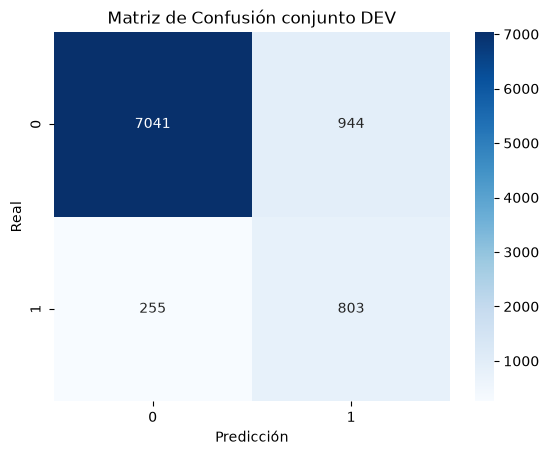

In [ ]:
# Realizar predicciones en el conjunto de prueba
y_pred_proba = model.predict(X_dev_transformed)
y_pred = (y_pred_proba > 0.7).astype(int) # Convertir probabilidades a clases binarias (0 o 1)

# Mostrar el reporte de clasificación
print("\nReporte de clasificación en el conjunto de prueba:")
print(classification_report(y_dev, y_pred))

# Mostrar la matriz de confusión
cm = confusion_matrix(y_dev, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión conjunto DEV')
plt.show()

## COMPARACIÓN DE MODELOS

| Modelo baseline regresión logística | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| 1. Sin Valores "unknown" y todas las variables | 0.9016 | 0.6474 | 0.3488 | 0.4533 |
| 2. Sin `poutcome` | 0.8944 | 0.6084 | 0.2732 | 0.3770 |
| 3. Sin `poutcome` y `contact` | 0.8919 | 0.5889 | 0.2505 | 0.3515 |
| 4. Sin `poutcome`, `contact` y `duration` | 0.8846 | 0.5443 | 0.0813 | 0.1414 |
| 5. KNN para `Job` y `Education` sin `poutcome`, `contact` y `duration` | 0.8850 | 0.5563 | 0.0841 | 0.1461 |
| 6. KNN para `Job` y `Education` sin `poutcome` ni `contact` | 0.8920 | 0.5898 | 0.2514 | 0.3526 |
| 7. Igual pero con ténica **SMOTE** | 0.8246 | 0.3792 | 0.7836 | 0.5111 |
| 8. Igual pero con ténica **Tomek Link** | 0.8940 | 0.5898 | 0.3072 | 0.4040 |
| 9. Primero con **Tomek Link** y luego con **SMOTE**| 0.8217 | 0.3762 | 0.7958 | 0.5109 |
| 9. Primero con **SMOTE** y luego con **Tomek Link** | 0.8244 | 0.3789 | 0.7836 | 0.5108 |





| Red neuronal regularizada y con dropout | Precision | Recall | F1-score | Época de detención |
|---|---:|---:|---:|---:|
| 1. Sin valores "unknown" y todas las variables  | 0.38 | 0.88 | 0.53 | No informado |
| 2. Sin `poutcome` | 0.37 | 0.90 | 0.53 | 66 |
| 3. Sin `poutcome` y `contact` | 0.36 | 0.90 | 0.51 | 59 |
| 4. Sin `poutcome`, `contact` y `duration` | 0.24 | 0.68 | 0.36 | 49 |
| 5. KNN para `Job` y `Education` sin `poutcome`, `contact` y `duration` | 0.24 | 0.69 | 0.35 | 61 |
| 6. KNN para `Job` y `Education` sin `poutcome` ni `contact` | 0.34 | 0.90 | 0.49 | 46 |
| 7. Con oversampling técnica **SMOTE** | 0.38 | 0.86 | 0.53 | 61 |
| 8. Con undersampling técnica **Tomek Link** | 0.34 | 0.91 | 0.49 | 67|
| 9. Primero con **Tomek Link** y luego **SMOTE** | 0.39 | 0.87 | 0.54 | 42|
| 10. Primero con  **SMOTE** y luego **Tomek Link** | 0.40 | 0.87 | 0.55 | 72|